In [1]:
import os
for dirname, _, filenames in os.walk("/kaggle/input"):
    print(dirname, len(filenames))
    break
print(os.listdir("/kaggle/input"))

/kaggle/input 0
['competitions']


In [2]:
import os

DATA = "/kaggle/input/competitions/ai-of-god-5/participant_data"
print(os.listdir(DATA))

['sample_submission.csv', 'train_images', 'train.csv', 'data_description.md', 'test_images']


In [3]:
import pandas as pd 
from PIL import Image 

train = pd.read_csv(f"{DATA}/train.csv")
test_files = os.listdir(f"{DATA}/test_images")

print(train.shape)
print(train.head())
print("Test images:", len(test_files))

(3087, 2)
                               image_id animal_class
0          000dc07b2b676f5d0ec0acf9.png     reindeer
1  0063d33c0996495e9337062ad3f13319.png     antelope
2          007227c159bdba58d63406ca.png        sheep
3  00838ab89a624affb0b36cd676d511c4.png          bee
4          0099c1e57da598c85cef9c22.png        snake
Test images: 1179


In [4]:
widths = []
heights = []
modes =[]
#class balance checking 
counts = train["animal_class"].value_counts()
print(counts.head(5))
print(counts.tail(5))
print("min:", counts.min(), "max:",counts.max())

#widths,heights,modes = [],[],[]
for name in train["image_id"]:
    img = Image.open(f"{DATA}/train_images/{name}")
    widths.append(img.width)
    heights.append(img.height)
    modes.append(img.mode)

train["w"] = widths
train["h"] = heights
train["aspect"] = train["w"]/train["h"]

print(set(modes))
print(train[["w","h","aspect"]].describe())


animal_class
hedgehog        51
grasshopper     51
hare            51
hippopotamus    51
hyena           51
Name: count, dtype: int64
animal_class
starfish          41
seal              41
pelecaniformes    41
raccoon           34
jellyfish         23
Name: count, dtype: int64
min: 23 max: 51
{'RGB'}
                 w            h       aspect
count  3087.000000  3087.000000  3087.000000
mean    824.515387   578.611273     1.495233
std     762.785628   563.452774     0.375361
min     145.000000   120.000000     0.415820
25%     275.000000   183.000000     1.333333
50%     496.000000   350.000000     1.501587
75%    1200.000000   768.000000     1.777778
max    4854.000000  4064.000000     3.500000


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

X = train[["w", "h", "aspect"]]
y = train["animal_class"]

score = cross_val_score(RandomForestClassifier(n_estimators=200), X, y, cv=5).mean()
print("Accuracy from size alone:", score)
print("Random guessing would give:", 1 / 72)

In [ ]:
import numpy as np

def count_colors(path):
    arr = np.array(Image.open(path).convert("RGB"))
    return len(np.unique(arr.reshape(-1, 3), axis=0))

sample = train.sample(200, random_state=0)
sample_colors = [count_colors(f"{DATA}/train_images/{n}") for n in sample["image_id"]]

print(pd.Series(sample_colors).describe())

In [ ]:
#Every file has a "fingerprint" (an MD5 hash). Two identical files give the same fingerprint.
#So I am computing one fingerprint per image and look for repeats.
# def file_hash(path):
#    with open(path, "rb") as f:
#         return hashlib.md5(f.read()).hexdigest()

# print(file_hash(path))   # should match Piece 1
# train_hashes = []
# for name in train["image_id"]:
#     train_hashes.append(file_hash(f"{DATA}/train_images/{name}"))

# train["hash"] = train_hashes
# test_hashes = set()
# for name in test_files:
#     test_hashes.add(file_hash(f"{DATA}/test_images/{name}"))
# print("Duplicates inside train:", train["hash"].duplicated().sum())
# print("Train images also in test:", train["hash"].isin(test_hashes).sum())
#Output
#03254adfd8b5e99d31beb9080b2816d2
#<function file_hash at 0x7b2a710c3100>
#Duplicates inside train: 0
#Train images also in test: 0

In [10]:
import numpy as np
import pandas as pd
from PIL import Image

# Train sizes were already computed (train["w"], train["h"], train["aspect"]).
# Compute the same for test.
test_df = pd.DataFrame({"image_id": test_files})
tw, th, tm = [], [], []
for name in test_df["image_id"]:
    with Image.open(f"{DATA}/test_images/{name}") as img:
        tw.append(img.width); th.append(img.height); tm.append(img.mode)

test_df["w"], test_df["h"] = tw, th
test_df["aspect"] = test_df["w"] / test_df["h"]

print("Test modes:", set(tm))
print("\n--- TRAIN ---")
print("unique (w,h) sizes:", train[["w", "h"]].drop_duplicates().shape[0], "of", len(train))
print(train[["w", "h", "aspect"]].describe().round(2))
print("\n--- TEST ---")
print("unique (w,h) sizes:", test_df[["w", "h"]].drop_duplicates().shape[0], "of", len(test_df))
print(test_df[["w", "h", "aspect"]].describe().round(2))

print("\nMost common sizes (train):")
print(train.groupby(["w", "h"]).size().sort_values(ascending=False).head(5))
print("\nMost common sizes (test):")
print(test_df.groupby(["w", "h"]).size().sort_values(ascending=False).head(5))

Test modes: {'RGB'}

--- TRAIN ---
unique (w,h) sizes: 1203 of 3087
             w        h   aspect
count  3087.00  3087.00  3087.00
mean    824.52   578.61     1.50
std     762.79   563.45     0.38
min     145.00   120.00     0.42
25%     275.00   183.00     1.33
50%     496.00   350.00     1.50
75%    1200.00   768.00     1.78
max    4854.00  4064.00     3.50

--- TEST ---
unique (w,h) sizes: 564 of 1179
             w        h   aspect
count  1179.00  1179.00  1179.00
mean    783.28   549.20     1.50
std     690.41   511.56     0.37
min     147.00   129.00     0.45
25%     275.00   183.00     1.33
50%     480.00   350.00     1.50
75%    1200.00   720.00     1.78
max    4928.00  3168.00     3.50

Most common sizes (train):
w    h  
275  183    258
300  168    199
259  194    138
225  225     99
299  168     46
dtype: int64

Most common sizes (test):
w    h  
275  183    118
300  168     61
259  194     40
225  225     37
299  168     31
dtype: int64


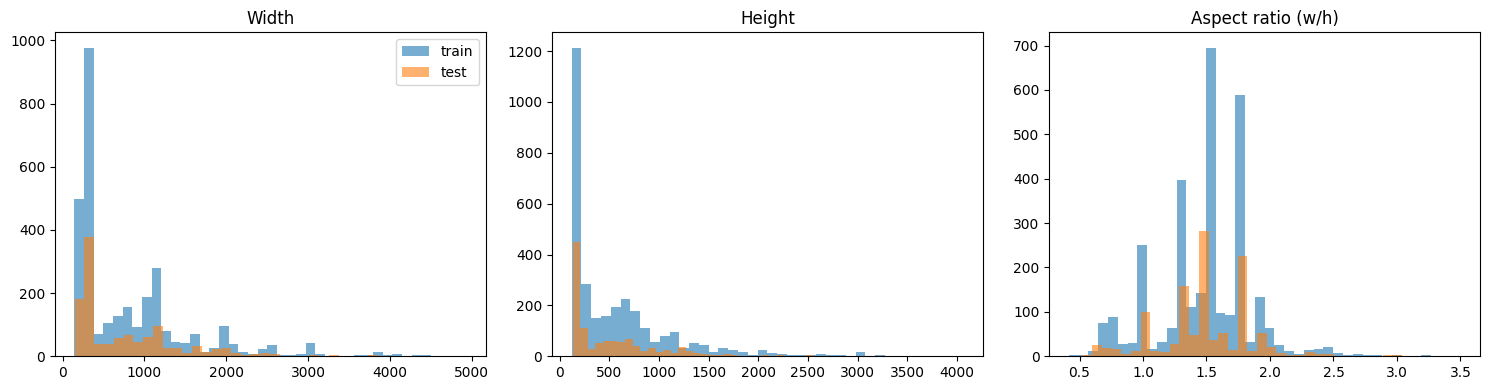

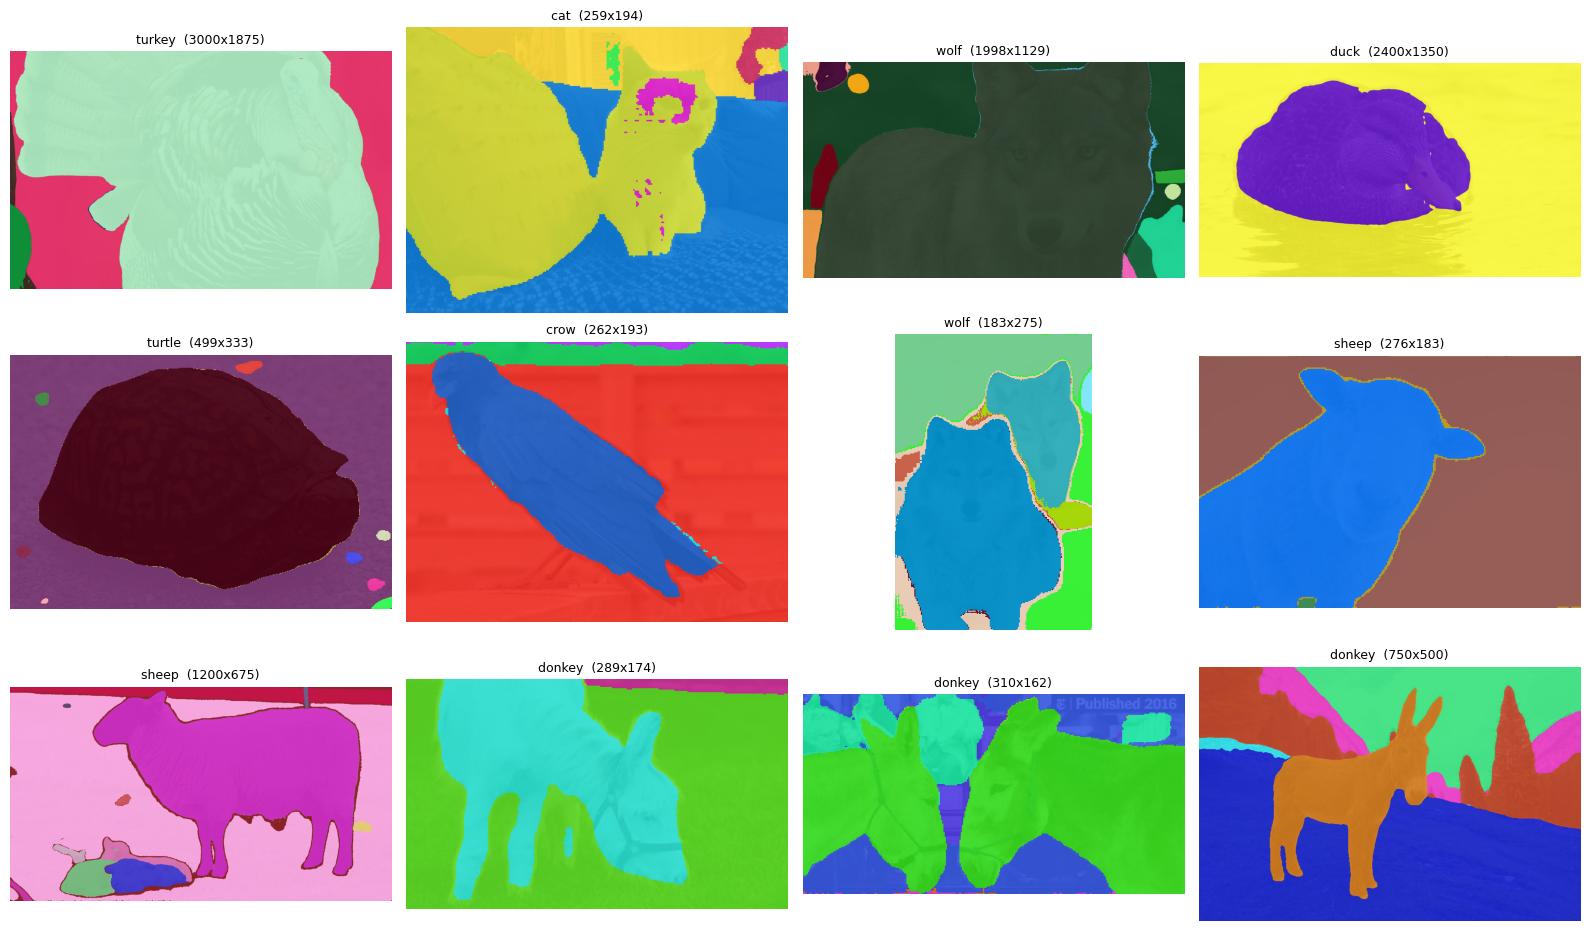

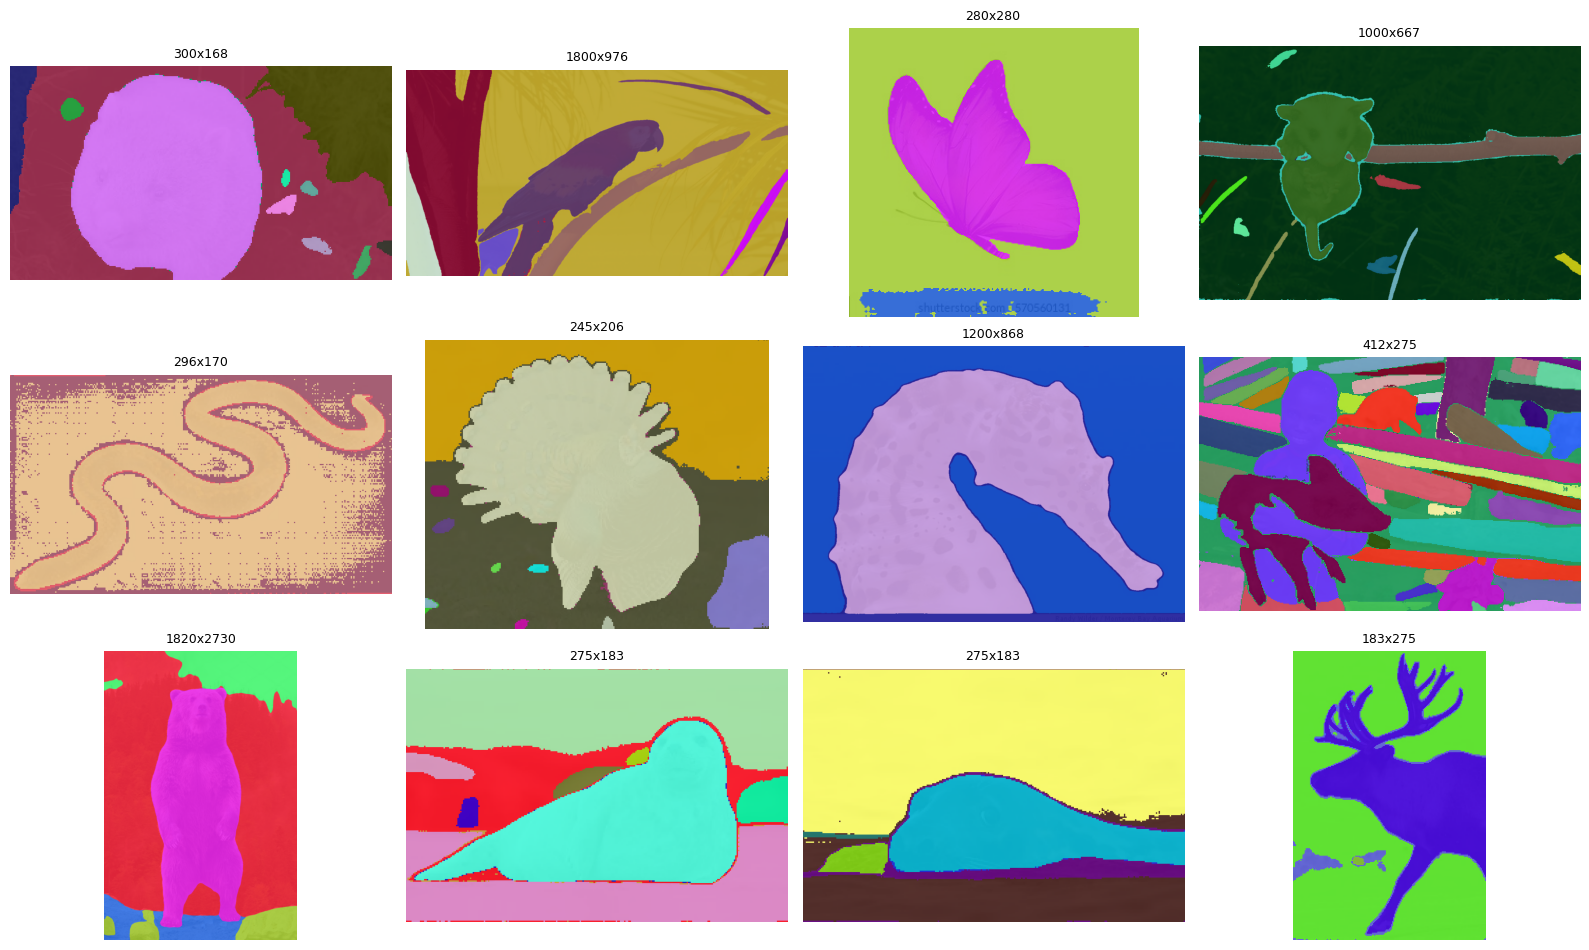

In [11]:
import matplotlib.pyplot as plt

# 1) Size distributions: train vs test
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(train["w"], bins=40, alpha=0.6, label="train"); ax[0].hist(test_df["w"], bins=40, alpha=0.6, label="test")
ax[0].set_title("Width"); ax[0].legend()
ax[1].hist(train["h"], bins=40, alpha=0.6, label="train"); ax[1].hist(test_df["h"], bins=40, alpha=0.6, label="test")
ax[1].set_title("Height")
ax[2].hist(train["aspect"], bins=40, alpha=0.6, label="train"); ax[2].hist(test_df["aspect"], bins=40, alpha=0.6, label="test")
ax[2].set_title("Aspect ratio (w/h)")
plt.tight_layout(); plt.show()

# 2) Random TRAIN images with labels
def show_train(n=12, seed=None, cols=4):
    rows = int(np.ceil(n / cols))
    sample = train.sample(n, random_state=seed)
    plt.figure(figsize=(4 * cols, 3.2 * rows))
    for i, (_, r) in enumerate(sample.iterrows()):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(Image.open(f"{DATA}/train_images/{r.image_id}").convert("RGB"))
        plt.title(f"{r.animal_class}  ({r.w}x{r.h})", fontsize=9)
        plt.axis("off")
    plt.tight_layout(); plt.show()

# 3) Random TEST images (no labels)
def show_test(n=12, seed=None, cols=4):
    rows = int(np.ceil(n / cols))
    sample = test_df.sample(n, random_state=seed)
    plt.figure(figsize=(4 * cols, 3.2 * rows))
    for i, (_, r) in enumerate(sample.iterrows()):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(Image.open(f"{DATA}/test_images/{r.image_id}").convert("RGB"))
        plt.title(f"{r.w}x{r.h}", fontsize=9)
        plt.axis("off")
    plt.tight_layout(); plt.show()

show_train(12, seed=1)
show_test(12, seed=1)

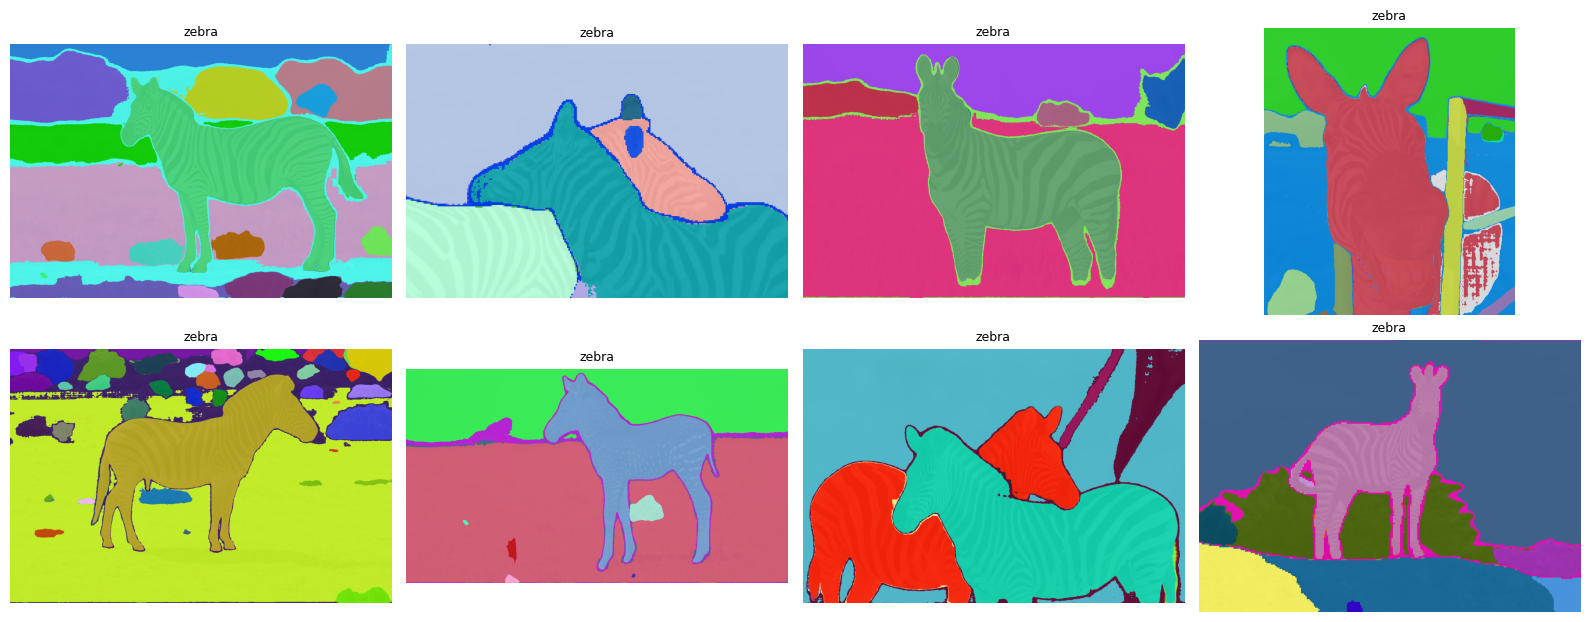

In [12]:
def show_class(cls, n=8, cols=4):
    rows = int(np.ceil(n / cols))
    sample = train[train.animal_class == cls].sample(n, random_state=0)
    plt.figure(figsize=(4 * cols, 3.2 * rows))
    for i, (_, r) in enumerate(sample.iterrows()):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(Image.open(f"{DATA}/train_images/{r.image_id}").convert("RGB"))
        plt.title(cls, fontsize=9); plt.axis("off")
    plt.tight_layout(); plt.show()

show_class("zebra")

In [20]:
import os, math, random
import numpy as np, pandas as pd
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
from sklearn.model_selection import StratifiedKFold

DATA = "/kaggle/input/competitions/ai-of-god-5/participant_data"
IMG_SIZE = 320
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # normalization (ImageNet)

train = pd.read_csv(f"{DATA}/train.csv")
test_df = pd.read_csv(f"{DATA}/sample_submission.csv")[["image_id"]]

classes = sorted(train.animal_class.unique())
label2idx = {c: i for i, c in enumerate(classes)}
train["label"] = train.animal_class.map(label2idx)

train["fold"] = -1
skf = StratifiedKFold(5, shuffle=True, random_state=42)
for f, (_, v) in enumerate(skf.split(train, train.label)):
    train.loc[train.index[v], "fold"] = f

In [21]:
def letterbox(img, size, fill=(124, 116, 104)):
    w, h = img.size; s = size / max(w, h)
    nw, nh = max(1, round(w*s)), max(1, round(h*s))
    canvas = Image.new("RGB", (size, size), fill)
    canvas.paste(img.resize((nw, nh), Image.BICUBIC), ((size-nw)//2, (size-nh)//2))
    return canvas

In [25]:
class TrainTF:
    def __call__(self, img):
        w, h = img.size
        k = math.sqrt(random.uniform(0.65, 1.0)) # mild random crop
        cw, ch = max(8, int(w * k)), max(8, int(h * k))
        x0, y0 = random.randint(0, w - cw), random.randint(0, h - ch)
        img = img.crop((x0, y0, x0 + cw, y0 + ch))
        
        # 1. Spatial augmentations
        if random.random() < 0.5:
            img = TF.hflip(img) # horizontal flip
            
        # 2. Color augmentations (BEFORE padding)
        img = TF.adjust_hue(img, random.uniform(-0.5, 0.5)) # hue rotation
        
        # Channel shuffle using PIL
        bands = list(img.split())
        random.shuffle(bands)
        img = Image.merge("RGB", bands)
        
        # 3. Apply padding to the augmented image
        img = letterbox(img, IMG_SIZE)
        
        # 4. Convert to tensor and normalize
        x = TF.to_tensor(img)
        return TF.normalize(x, MEAN, STD)
class EvalTF:                                                      # val/test: no augmentation
    def __call__(self, img):
        return TF.normalize(TF.to_tensor(letterbox(img, IMG_SIZE)), MEAN, STD)

In [26]:
class ImgDS(Dataset):
    def __init__(self, df, folder, tf, labeled=True):
        self.df, self.folder, self.tf, self.labeled = df.reset_index(drop=True), folder, tf, labeled
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        x = self.tf(Image.open(f"{self.folder}/{r.image_id}").convert("RGB"))
        return (x, int(r.label)) if self.labeled else (x, r.image_id)

tr, va = train[train.fold != 0], train[train.fold == 0]
dl_tr = DataLoader(ImgDS(tr, f"{DATA}/train_images", TrainTF()), batch_size=32, shuffle=True, num_workers=2, drop_last=True)
dl_va = DataLoader(ImgDS(va, f"{DATA}/train_images", EvalTF()), batch_size=32, num_workers=2)
dl_te = DataLoader(ImgDS(test_df, f"{DATA}/test_images", EvalTF(), labeled=False), batch_size=32, num_workers=2)

torch.Size([32, 3, 320, 320]) torch.Size([32])


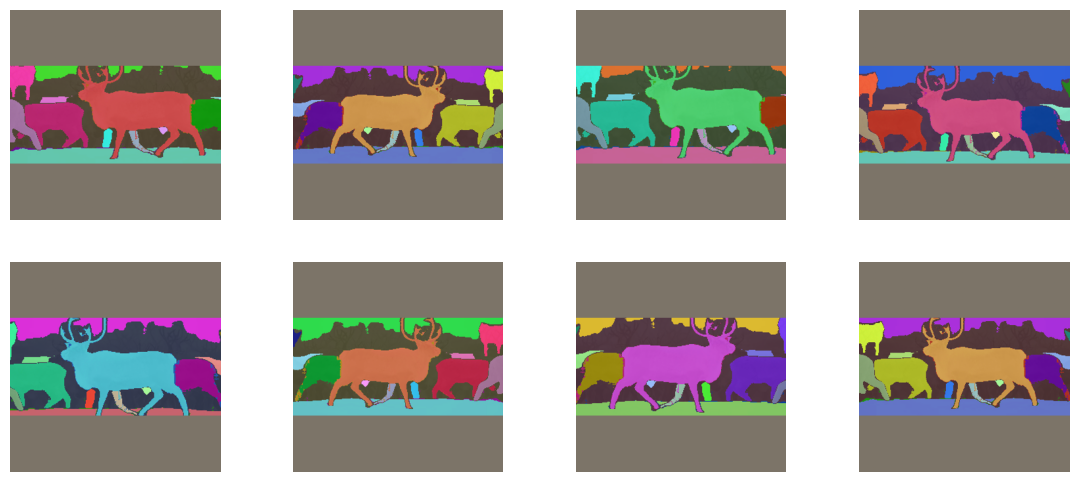

In [27]:
import matplotlib.pyplot as plt
xb, yb = next(iter(dl_tr)); print(xb.shape, yb.shape)   # expect [32,3,288,288] and [32]

def show(x):
    m = torch.tensor(MEAN).view(3,1,1); s = torch.tensor(STD).view(3,1,1)
    return (x*s + m).clamp(0,1).permute(1,2,0).numpy()

img = Image.open(f"{DATA}/train_images/{train.image_id[0]}").convert("RGB")
plt.figure(figsize=(14,6))
for i in range(8):
    plt.subplot(2,4,i+1); plt.imshow(show(TrainTF()(img))); plt.axis("off")
plt.show()

In [31]:
#Step 1: imports, model, and color stats
import timm, torch.nn as nn
from sklearn.metrics import f1_score, accuracy_score

device = "cuda"
assert torch.cuda.is_available(), "Turn on a GPU: Settings -> Accelerator"
torch.backends.cudnn.benchmark = True
idx2label = {i: c for c, i in label2idx.items()}

def build_model(pretrained=True):
    return timm.create_model("tf_efficientnetv2_s.in21k_ft_in1k",
                             pretrained=pretrained, num_classes=len(classes), drop_rate=0.2)

m = build_model()
MEAN, STD = m.pretrained_cfg["mean"], m.pretrained_cfg["std"]   # use the model's own stats
print("mean/std:", MEAN, STD); del m

mean/std: (0.5, 0.5, 0.5) (0.5, 0.5, 0.5)


In [32]:
#Step 2: loaders and a prediction helper
def make_loaders(fold, bs=32, workers=4):
    tr, va = train[train.fold != fold], train[train.fold == fold]
    dl_tr = DataLoader(ImgDS(tr, f"{DATA}/train_images", TrainTF()), batch_size=bs,
                       shuffle=True, drop_last=True, num_workers=workers, pin_memory=True)
    dl_va = DataLoader(ImgDS(va, f"{DATA}/train_images", EvalTF()), batch_size=bs,
                       num_workers=workers, pin_memory=True)
    return dl_tr, dl_va

@torch.no_grad()
def predict_probs(model, dl, tta=False):
    """Returns class probabilities in dataset order. tta=True averages 4 views."""
    model.eval(); outs = []
    for x, _ in dl:
        x = x.to(device)
        views = [x] + ([x.flip(3), x[:, [2, 1, 0]], x[:, [2, 1, 0]].flip(3)] if tta else [])
        with torch.autocast("cuda", dtype=torch.float16):
            p = sum(model(v).float().softmax(1) for v in views) / len(views)
        outs.append(p.cpu())
    return torch.cat(outs)

In [33]:
#Step 3: training function
def run_fold(fold, epochs=15, lr=3e-4, bs=32):
    dl_tr, dl_va = make_loaders(fold, bs)
    va_labels = train[train.fold == fold].label.values
    model = build_model().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, pct_start=0.1,
                                                total_steps=epochs * len(dl_tr))
    crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    scaler = torch.amp.GradScaler("cuda")
    best, path = 0.0, f"/kaggle/working/effv2s_fold{fold}.pt"

    for ep in range(epochs):
        model.train(); tot = 0
        for x, y in dl_tr:
            x, y = x.to(device, non_blocking=True), y.to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16):
                loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(y)
        pred = predict_probs(model, dl_va).argmax(1).numpy()
        f1 = f1_score(va_labels, pred, average="macro"); acc = accuracy_score(va_labels, pred)
        print(f"ep {ep+1:02d} | loss {tot/(len(dl_tr)*bs):.3f} | val acc {acc:.3f} | val macro-F1 {f1:.3f}")
        if f1 > best:
            best = f1; torch.save(model.state_dict(), path)
    print("best val macro-F1:", round(best, 4)); return path

In [34]:
#Step 4: train on fold 0 and check per-class results
ckpt0 = run_fold(fold=0, epochs=15)

# per-class F1 with the best checkpoint (+TTA)
model = build_model(pretrained=False).to(device)
model.load_state_dict(torch.load(ckpt0, map_location=device))
_, dl_va = make_loaders(0)
va_labels = train[train.fold == 0].label.values
pred = predict_probs(model, dl_va, tta=True).argmax(1).numpy()
print("val macro-F1 with TTA:", round(f1_score(va_labels, pred, average="macro"), 4))
per_class = pd.Series(f1_score(va_labels, pred, average=None, labels=list(range(len(classes)))), index=classes)
print(per_class.sort_values().head(10))     # 10 weakest classes

/tmp/ipykernel_49/2049635548.py:20: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


ep 01 | loss 5.087 | val acc 0.146 | val macro-F1 0.126
ep 02 | loss 2.731 | val acc 0.756 | val macro-F1 0.746
ep 03 | loss 1.388 | val acc 0.848 | val macro-F1 0.845
ep 04 | loss 1.083 | val acc 0.869 | val macro-F1 0.866
ep 05 | loss 0.971 | val acc 0.893 | val macro-F1 0.892
ep 06 | loss 0.918 | val acc 0.896 | val macro-F1 0.894
ep 07 | loss 0.884 | val acc 0.911 | val macro-F1 0.910
ep 08 | loss 0.865 | val acc 0.916 | val macro-F1 0.914
ep 09 | loss 0.845 | val acc 0.917 | val macro-F1 0.916
ep 10 | loss 0.838 | val acc 0.922 | val macro-F1 0.920
ep 11 | loss 0.832 | val acc 0.922 | val macro-F1 0.921
ep 12 | loss 0.825 | val acc 0.922 | val macro-F1 0.921
ep 13 | loss 0.823 | val acc 0.921 | val macro-F1 0.920
ep 14 | loss 0.821 | val acc 0.916 | val macro-F1 0.914
ep 15 | loss 0.821 | val acc 0.921 | val macro-F1 0.919
best val macro-F1: 0.9207
val macro-F1 with TTA: 0.9206
rat           0.666667
squid         0.705882
bear          0.769231
pig           0.777778
parrot      

In [35]:
def predict_test(ckpts, tta=True):
    dl_te = DataLoader(ImgDS(test_df, f"{DATA}/test_images", EvalTF(), labeled=False),
                       batch_size=32, num_workers=4)
    total = 0
    for p in ckpts:
        m = build_model(pretrained=False).to(device)
        m.load_state_dict(torch.load(p, map_location=device))
        total = total + predict_probs(m, dl_te, tta)
    return total / len(ckpts)

CKPTS = [ckpt0]                      # later: add more fold checkpoints here to ensemble
probs = predict_test(CKPTS)

sub = pd.DataFrame({"image_id": test_df.image_id.values,
                    "animal_class": [idx2label[i] for i in probs.argmax(1).tolist()]})
sub.to_csv("/kaggle/working/submission.csv", index=False)

# format checks
assert len(sub) == 1179 and sub.image_id.is_unique and sub.animal_class.isin(classes).all()
print(sub.head()); print(sub.animal_class.value_counts().head())

                               image_id animal_class
0          6eab26f8b156fda90e1bc819.png   woodpecker
1  483f71af1c174ab2a0c31a836267227d.png     antelope
2  563878772a3f47ce98cf9c10039a0219.png   chimpanzee
3  9aa782974228482390c1a237408a967a.png      hamster
4  3ed553219cf049b8bd9a65c300b02fb0.png          cat
animal_class
wolf     24
pig      22
zebra    21
crow     20
seal     20
Name: count, dtype: int64
